In [1]:
# From ref design
from pynq import Overlay
import xrfclk
from pynq import PL

# ADC
from adc_scope import AdcScope
import matplotlib.pyplot as plt
%matplotlib inline

# DAC
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [2]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals
ol = Overlay("awg_adc_v5.bit")         # after xrfclk.set_ref_clks(...)

In [3]:
awg = AWG(window=1000 * ns, bitfile=ol)

Window = 0.9993 us  (9824 samples, 614 clock cycles)  [requested 1.0000 us]


1e-09 9830400000.0 5.000000000000001e-07 4915 614
Window: 0.9993 us = 9824 samples = 614 clock cycles (MAX_POINTS)
DAC full scale: +-0.250 V peak (CW -2.04 dBm into 50 ohm)
  DAC A slot x: peak   100.00 mV  (-10.00 dBm)
  DAC A slot z: peak     0.00 mV  (  -inf dBm)
  DAC B slot x: peak   100.00 mV  (-10.00 dBm)
  DAC B slot z: peak     0.00 mV  (  -inf dBm)


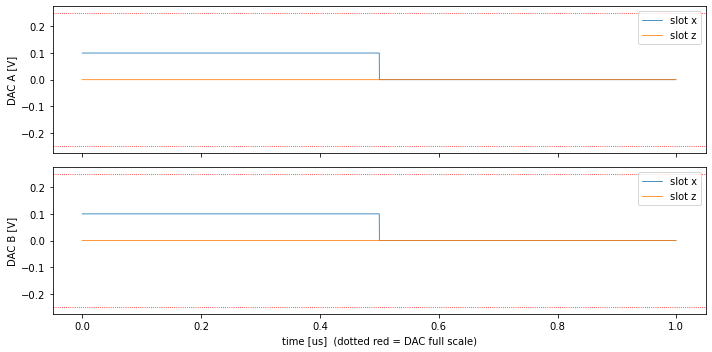

In [20]:
# mysig = 0.2 * np.sin(2*np.pi*100e6*awg.t)  # 164 mV peak

pulse_width = 500 * ns
pulsewidth_insamples = round(pulse_width * DAC_SR)

print(ns, DAC_SR, pulse_width, pulsewidth_insamples, awg.max_points)

mypulse = 0.1 * np.append( np.ones(pulsewidth_insamples), np.zeros(len(awg.t) - pulsewidth_insamples) )

awg.set_waveform(dac="A", slot="x", content=mypulse)
awg.set_waveform(dac="B", slot="x", content=mypulse)
# Not played by default
awg.set_waveform(dac="A", slot="z", content=0)
awg.set_waveform(dac="B", slot="z", content=0)
awg.summary()   # peak level of every slot (+ clipping warning)
awg.plot()
plt.show()

In [ ]:
awg.connect()    # load bitstream, program clocks, reset the AWG logic

In [21]:
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs

DMA upload took 0.0067 s
Playing on DAC A, B


In [22]:
sc = AdcScope(ol)                      # starts the ADC clock (MMCM) and checks the ADC streams

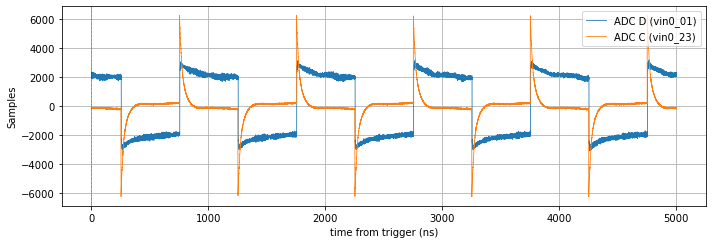

In [23]:
sc.configure(trigger="immediate", pre_ns=0, length_ns=10*pulse_width/ns)
t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in samples
sc.plot(t, y, ylabel="Samples")

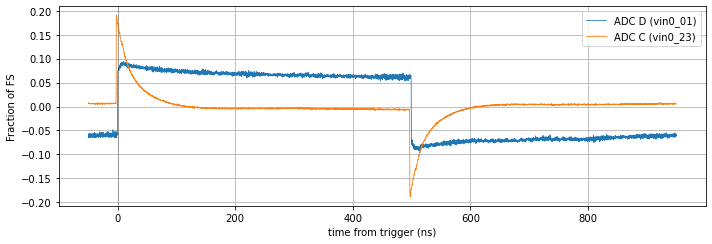

In [24]:
# Can use rising/falling edges. TODO make it choosable between ADC channels.
sc.configure(trigger="rising", level=0.05, pre_ns=pulse_width/ns/10, length_ns=2*pulse_width/ns)
t, y = sc.acquire() # t in ns, 0 = trigger; y in samples
sc.plot(t, y, ylabel="Fraction of FS")

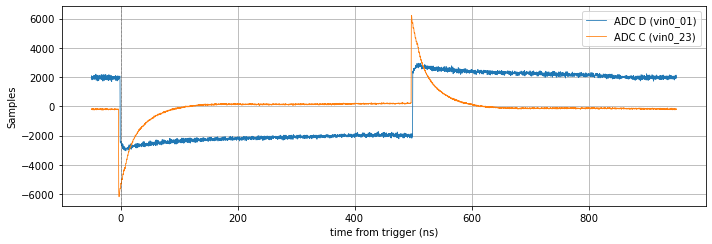

In [25]:
# Can also autocal on AWG, get rid of the delay DAC -> ADC. 
sc.calibrate_awg(dac="A", adc="D")
sc.configure(trigger="dac_a", pre_ns=pulse_width/ns/10, length_ns=2*pulse_width/ns)

t, y = sc.acquire() # t in ns, 0 = trigger; y in fraction of full scale

t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in samples
sc.plot(t, y, ylabel="Samples")

1e-09 9830400000.0 1e-08 98 614
DMA upload took 0.0066 s
Playing on DAC A, B
107.05061018555654 0.49015240148053824


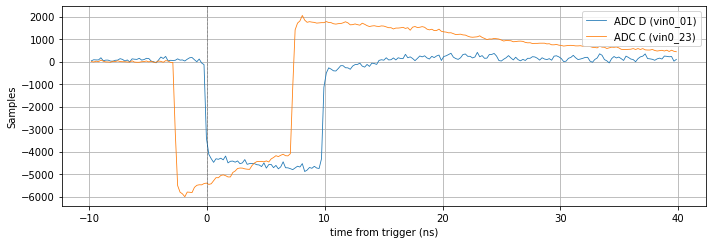

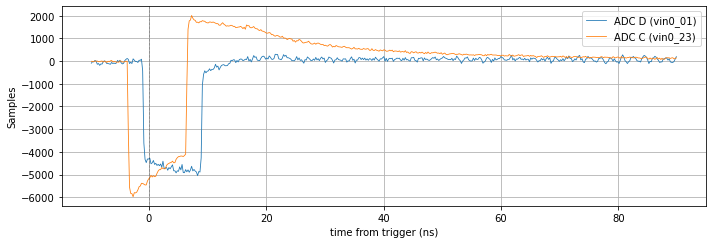

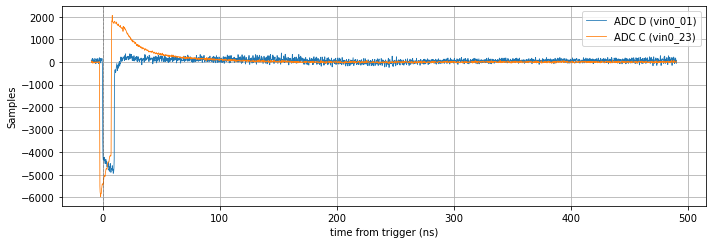

In [32]:
pulse_width = 10 * ns
pulsewidth_insamples = round(pulse_width * DAC_SR)

print(ns, DAC_SR, pulse_width, pulsewidth_insamples, awg.max_points)

mypulse = 0.1 * np.append( np.ones(pulsewidth_insamples), np.zeros(len(awg.t) - pulsewidth_insamples) )

awg.set_waveform(dac="A", content=mypulse)
awg.set_waveform(dac="B", content=mypulse)
# Not played by default
awg.set_waveform(dac="A", content=0, slot="z")
awg.set_waveform(dac="B", content=0, slot="z")
# awg.connect()    # load bitstream, program clocks, reset the AWG logic
awg.upload()     # send waveforms + length to the board RAM
awg.start()      # enable the outputs


offset_ns, spread_ns = sc.calibrate_awg(dac="A", adc="D")
print(offset_ns, spread_ns)

sc.configure(trigger="dac_a", pre_ns=pulse_width/ns, length_ns=5*pulse_width/ns)
t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in samples
sc.plot(t, y, ylabel="Samples")

sc.configure(trigger="dac_a", pre_ns=pulse_width/ns, length_ns=10*pulse_width/ns)
t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in samples
sc.plot(t, y, ylabel="Samples")

sc.configure(trigger="dac_a", pre_ns=pulse_width/ns, length_ns=50*pulse_width/ns)
t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in samples
sc.plot(t, y, ylabel="Samples")